# Experiment 4 - Transfer Learning using Pre-Trained Vision Models


In [1]:
# Install kagglehub (usually already available in Colab, but just in case)
!pip install kagglehub -q


In [2]:
print("24BAD004")
print("K ADHITHYA")

24BAD004
K ADHITHYA


In [3]:
# Imports used throughout this notebook
import kagglehub
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import re


### PART A: DATASET PREPARATION


In [4]:
# 1. Download dataset from Kaggle
path = kagglehub.dataset_download("prasunroy/natural-images")
print("Dataset downloaded to:", path)


Using Colab cache for faster access to the 'natural-images' dataset.
Dataset downloaded to: /kaggle/input/natural-images


In [5]:
# Look at the folder structure so we know where the images are
for root, dirs, files in os.walk(path):
    level = root.replace(path, '').count(os.sep)
    indent = ' ' * 2 * level
    print(f"{indent}{os.path.basename(root)}/")
    if level < 3:
        for f in files[:3]:
            print(f"{indent}  {f}")


natural-images/
  natural_images/
    motorbike/
      motorbike_0786.jpg
      motorbike_0344.jpg
      motorbike_0360.jpg
    airplane/
      airplane_0181.jpg
      airplane_0500.jpg
      airplane_0433.jpg
    flower/
      flower_0092.jpg
      flower_0339.jpg
      flower_0093.jpg
    dog/
      dog_0555.jpg
      dog_0041.jpg
      dog_0667.jpg
    fruit/
      fruit_0521.jpg
      fruit_0862.jpg
      fruit_0718.jpg
    car/
      car_0208.jpg
      car_0395.jpg
      car_0331.jpg
    cat/
      cat_0069.jpg
      cat_0509.jpg
      cat_0448.jpg
    person/
      person_0399.jpg
      person_0016.jpg
      person_0223.jpg
  data/
    natural_images/
      motorbike/
      airplane/
      flower/
      dog/
      fruit/
      car/
      cat/
      person/


In [6]:
# The images sit in class-named subfolders under "natural_images"
data_root = os.path.join(path, "natural_images")
print("Data root:", data_root)

class_folders = sorted(os.listdir(data_root))
print("Classes found:", class_folders)


Data root: /kaggle/input/natural-images/natural_images
Classes found: ['airplane', 'car', 'cat', 'dog', 'flower', 'fruit', 'motorbike', 'person']


In [ ]:
# 2. Load and preprocess the images

file_paths = []
labels = []

for class_name in class_folders:
    class_folder_path = os.path.join(data_root, class_name)
    for file_name in os.listdir(class_folder_path):
        if file_name.lower().endswith(('.jpg', '.jpeg', '.png')):
            file_paths.append(os.path.join(class_folder_path, file_name))
            labels.append(class_name)

data_df = pd.DataFrame({
    'filepath': file_paths,
    'label': labels
})

print("Total images:", len(data_df))
print("Images per class:")
print(data_df['label'].value_counts())


Total images: 6899
Images per class:
label
fruit        1000
person        986
car           968
cat           885
flower        843
motorbike     788
airplane      727
dog           702
Name: count, dtype: int64


In [8]:
# 3. Split the dataset into training, validation, and testing sets
from sklearn.model_selection import train_test_split

# First split off a test set (15% of the data)
train_val_df, test_df = train_test_split(
    data_df,
    test_size=0.15,
    stratify=data_df['label'],
    random_state=42
)

print("Train+validation images:", len(train_val_df))
print("Test images:", len(test_df))


Train+validation images: 5864
Test images: 1035


In [ ]:
# ResNet-50 was trained with a specific preprocessing 
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet50 import preprocess_input

img_height = 224
img_width = 224
batch_size = 32

# Hold out 20% of the train+validation data for validation
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
)

test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator = train_datagen.flow_from_dataframe(
    train_val_df,
    x_col='filepath',
    y_col='label',
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    subset='training'
)

validation_generator = train_datagen.flow_from_dataframe(
    train_val_df,
    x_col='filepath',
    y_col='label',
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation'
)

test_generator = test_datagen.flow_from_dataframe(
    test_df,
    x_col='filepath',
    y_col='label',
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)

class_names = list(train_generator.class_indices.keys())

print("Number of classes:", len(class_names))
print("Number of training images:", train_generator.samples)
print("Number of validation images:", validation_generator.samples)
print("Number of test images:", test_generator.samples)


Found 4692 validated image filenames belonging to 8 classes.
Found 1172 validated image filenames belonging to 8 classes.
Found 1035 validated image filenames belonging to 8 classes.
Number of classes: 8
Number of training images: 4692
Number of validation images: 1172
Number of test images: 1035


Found 5864 validated image filenames belonging to 8 classes.


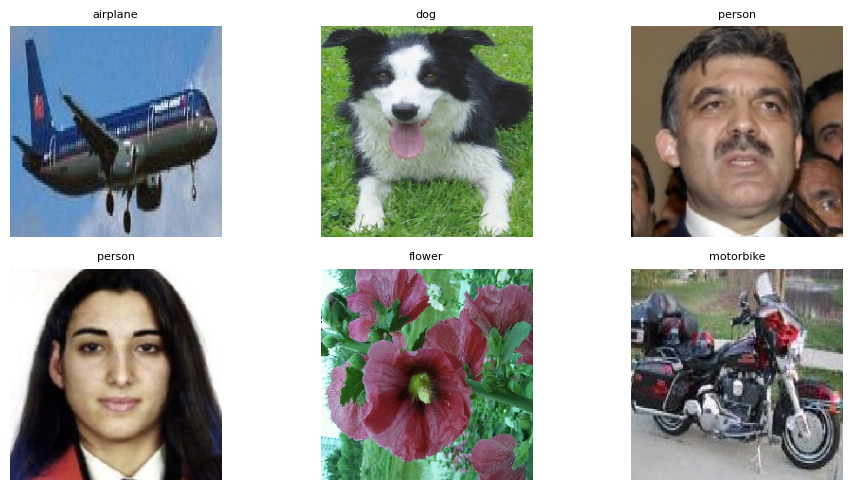

In [ ]:
# Few sample training images.
display_datagen = ImageDataGenerator(rescale=1./255)
display_generator = display_datagen.flow_from_dataframe(
    train_val_df,
    x_col='filepath',
    y_col='label',
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical'
)

images, labels_batch = next(display_generator)

plt.figure(figsize=(10, 5))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i])
    label_index = np.argmax(labels_batch[i])
    plt.title(display_generator.class_indices and list(display_generator.class_indices.keys())[label_index], fontsize=8)
    plt.axis('off')
plt.tight_layout()
plt.show()


### PART B: IMPLEMENTING TRANSFER LEARNING


In [11]:
# Load a pre-trained model: ResNet-50, without its original top (classification) layer
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model

base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(img_height, img_width, 3)
)

# Freeze the feature extraction layers
for layer in base_model.layers:
    layer.trainable = False

print("Number of layers in ResNet-50 base:", len(base_model.layers))


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Number of layers in ResNet-50 base: 175


In [12]:
# Replace the final classification layer according to the dataset classes
# (airplane, car, cat, dog, flower, fruit, motorbike, person)
num_classes = len(class_names)

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
predictions = Dense(num_classes, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 23,851,016 (90.98 MB)

 Trainable params: 263,304 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [13]:
# Compile the model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


### PART C: MODEL TRAINING AND PERFORMANCE EVALUATION



In [14]:
# Train the transfer learning model (stage 1: frozen base, train the new head only)
epochs = 8

history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=epochs
)


Epoch 1/8
147/147 ━━━━━━━━━━━━━━━━━━━━ 74s 408ms/step - accuracy: 0.9714 - loss: 0.0885 - val_accuracy: 0.9974 - val_loss: 0.0110
Epoch 2/8
147/147 ━━━━━━━━━━━━━━━━━━━━ 18s 120ms/step - accuracy: 0.9979 - loss: 0.0095 - val_accuracy: 0.9974 - val_loss: 0.0091
Epoch 3/8
147/147 ━━━━━━━━━━━━━━━━━━━━ 18s 119ms/step - accuracy: 0.9998 - loss: 0.0020 - val_accuracy: 0.9974 - val_loss: 0.0076
Epoch 4/8
147/147 ━━━━━━━━━━━━━━━━━━━━ 18s 121ms/step - accuracy: 0.9989 - loss: 0.0046 - val_accuracy: 0.9991 - val_loss: 0.0065
Epoch 5/8
147/147 ━━━━━━━━━━━━━━━━━━━━ 18s 122ms/step - accuracy: 0.9989 - loss: 0.0029 - val_accuracy: 0.9957 - val_loss: 0.0136
Epoch 6/8
147/147 ━━━━━━━━━━━━━━━━━━━━ 18s 121ms/step - accuracy: 0.9977 - loss: 0.0104 - val_accuracy: 0.9932 - val_loss: 0.0266
Epoch 7/8
147/147 ━━━━━━━━━━━━━━━━━━━━ 18s 121ms/step - accuracy: 0.9996 - loss: 0.0022 - val_accuracy: 0.9898 - val_loss: 0.0471
Epoch 8/8
147/147 ━━━━━━━━━━━━━━━━━━━━ 18s 119ms/step - accuracy: 0.9994 - loss: 0.0022 - 

**Fine-tuning (optional):** Natural Images has strong overlap with ImageNet classes
(airplane, car, cat, dog, etc. are essentially direct ImageNet categories), so the frozen
base alone should already do well. We still unfreeze the top few layers briefly for a small
extra boost.


In [15]:
# Unfreeze the top 10 layers of ResNet-50 for a short fine-tuning pass
for layer in base_model.layers[-10:]:
    layer.trainable = True

# Recompile with a lower learning rate since we are now updating pretrained weights
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

fine_tune_epochs = 3

history_fine = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=fine_tune_epochs
)


Epoch 1/3
147/147 ━━━━━━━━━━━━━━━━━━━━ 46s 212ms/step - accuracy: 0.9994 - loss: 0.0018 - val_accuracy: 0.9957 - val_loss: 0.0107
Epoch 2/3
147/147 ━━━━━━━━━━━━━━━━━━━━ 20s 132ms/step - accuracy: 0.9998 - loss: 0.0015 - val_accuracy: 0.9966 - val_loss: 0.0094
Epoch 3/3
147/147 ━━━━━━━━━━━━━━━━━━━━ 19s 130ms/step - accuracy: 0.9998 - loss: 3.2237e-04 - val_accuracy: 0.9966 - val_loss: 0.0094


In [16]:
# Record: Training accuracy, Validation accuracy, Training loss, Validation loss
# (using the final epoch after fine-tuning, since that reflects the final model)
final_train_acc = history_fine.history['accuracy'][-1]
final_val_acc = history_fine.history['val_accuracy'][-1]
final_train_loss = history_fine.history['loss'][-1]
final_val_loss = history_fine.history['val_loss'][-1]

print("Training Accuracy:", final_train_acc)
print("Validation Accuracy:", final_val_acc)
print("Training Loss:", final_train_loss)
print("Validation Loss:", final_val_loss)


Training Accuracy: 0.9997868537902832
Validation Accuracy: 0.9965870380401611
Training Loss: 0.00032236508559435606
Validation Loss: 0.009360493160784245


In [17]:
# Record: Test accuracy
test_loss, test_accuracy = model.evaluate(test_generator)
print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)


33/33 ━━━━━━━━━━━━━━━━━━━━ 11s 339ms/step - accuracy: 0.9990 - loss: 0.0015   
Test Accuracy: 0.9990338087081909
Test Loss: 0.0015213019214570522


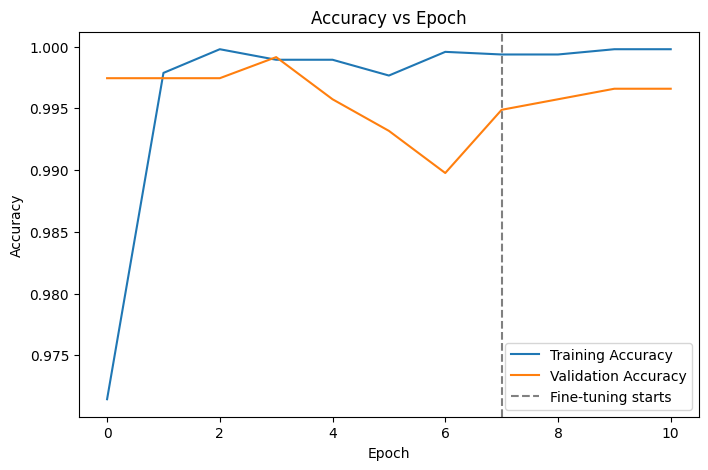

In [18]:
# Visualize: Accuracy vs Epoch (combining stage 1 training + fine-tuning)
combined_accuracy = history.history['accuracy'] + history_fine.history['accuracy']
combined_val_accuracy = history.history['val_accuracy'] + history_fine.history['val_accuracy']

plt.figure(figsize=(8, 5))
plt.plot(combined_accuracy, label='Training Accuracy')
plt.plot(combined_val_accuracy, label='Validation Accuracy')
plt.axvline(x=epochs - 1, color='gray', linestyle='--', label='Fine-tuning starts')
plt.title('Accuracy vs Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


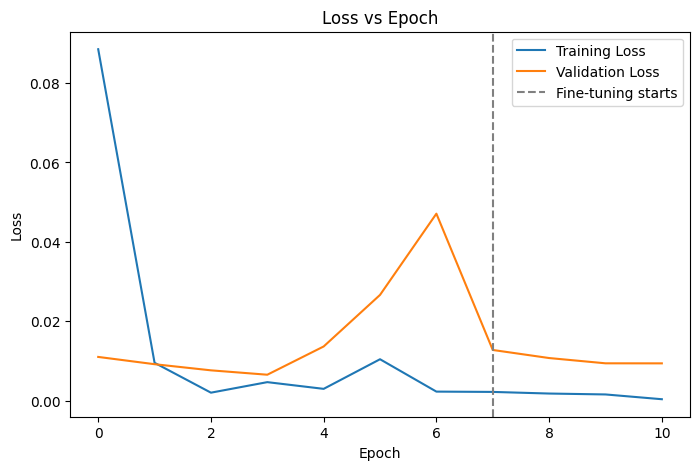

In [19]:
# Visualize: Loss vs Epoch (combining stage 1 training + fine-tuning)
combined_loss = history.history['loss'] + history_fine.history['loss']
combined_val_loss = history.history['val_loss'] + history_fine.history['val_loss']

plt.figure(figsize=(8, 5))
plt.plot(combined_loss, label='Training Loss')
plt.plot(combined_val_loss, label='Validation Loss')
plt.axvline(x=epochs - 1, color='gray', linestyle='--', label='Fine-tuning starts')
plt.title('Loss vs Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


### PART D: USING HUGGING FACE PRE-TRAINED MODELS


In [20]:
# Install the Hugging Face transformers library
!pip install transformers -q


In [21]:
# Load a pre-trained vision model from Hugging Face: ViT (Vision Transformer)
from transformers import ViTImageProcessor, ViTForImageClassification
from PIL import Image
import torch

processor = ViTImageProcessor.from_pretrained('google/vit-base-patch16-224')
vit_model = ViTForImageClassification.from_pretrained('google/vit-base-patch16-224')

print("Hugging Face ViT model loaded successfully")


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Hugging Face ViT model loaded successfully


In [22]:
# Pick one sample image per class to classify (8 classes total)
sample_image_paths = []
sample_true_labels = []

for class_folder in class_names:
    matching_rows = test_df[test_df['label'] == class_folder]
    if len(matching_rows) > 0:
        sample_image_paths.append(matching_rows.iloc[0]['filepath'])
        sample_true_labels.append(class_folder)

print("Sample images chosen:")
for p, l in zip(sample_image_paths, sample_true_labels):
    print(p, "-> true label:", l)


Sample images chosen:
/kaggle/input/natural-images/natural_images/airplane/airplane_0334.jpg -> true label: airplane
/kaggle/input/natural-images/natural_images/car/car_0895.jpg -> true label: car
/kaggle/input/natural-images/natural_images/cat/cat_0875.jpg -> true label: cat
/kaggle/input/natural-images/natural_images/dog/dog_0200.jpg -> true label: dog
/kaggle/input/natural-images/natural_images/flower/flower_0626.jpg -> true label: flower
/kaggle/input/natural-images/natural_images/fruit/fruit_0259.jpg -> true label: fruit
/kaggle/input/natural-images/natural_images/motorbike/motorbike_0609.jpg -> true label: motorbike
/kaggle/input/natural-images/natural_images/person/person_0676.jpg -> true label: person


Image: airplane_0334.jpg
True label: airplane
ViT predicted label: airliner
----------------------------------------
Image: car_0895.jpg
True label: car
ViT predicted label: sports car, sport car
----------------------------------------
Image: cat_0875.jpg
True label: cat
ViT predicted label: Egyptian cat
----------------------------------------
Image: dog_0200.jpg
True label: dog
ViT predicted label: Chihuahua
----------------------------------------
Image: flower_0626.jpg
True label: flower
ViT predicted label: pot, flowerpot
----------------------------------------
Image: fruit_0259.jpg
True label: fruit
ViT predicted label: Granny Smith
----------------------------------------
Image: motorbike_0609.jpg
True label: motorbike
ViT predicted label: disk brake, disc brake
----------------------------------------
Image: person_0676.jpg
True label: person
ViT predicted label: basketball
----------------------------------------


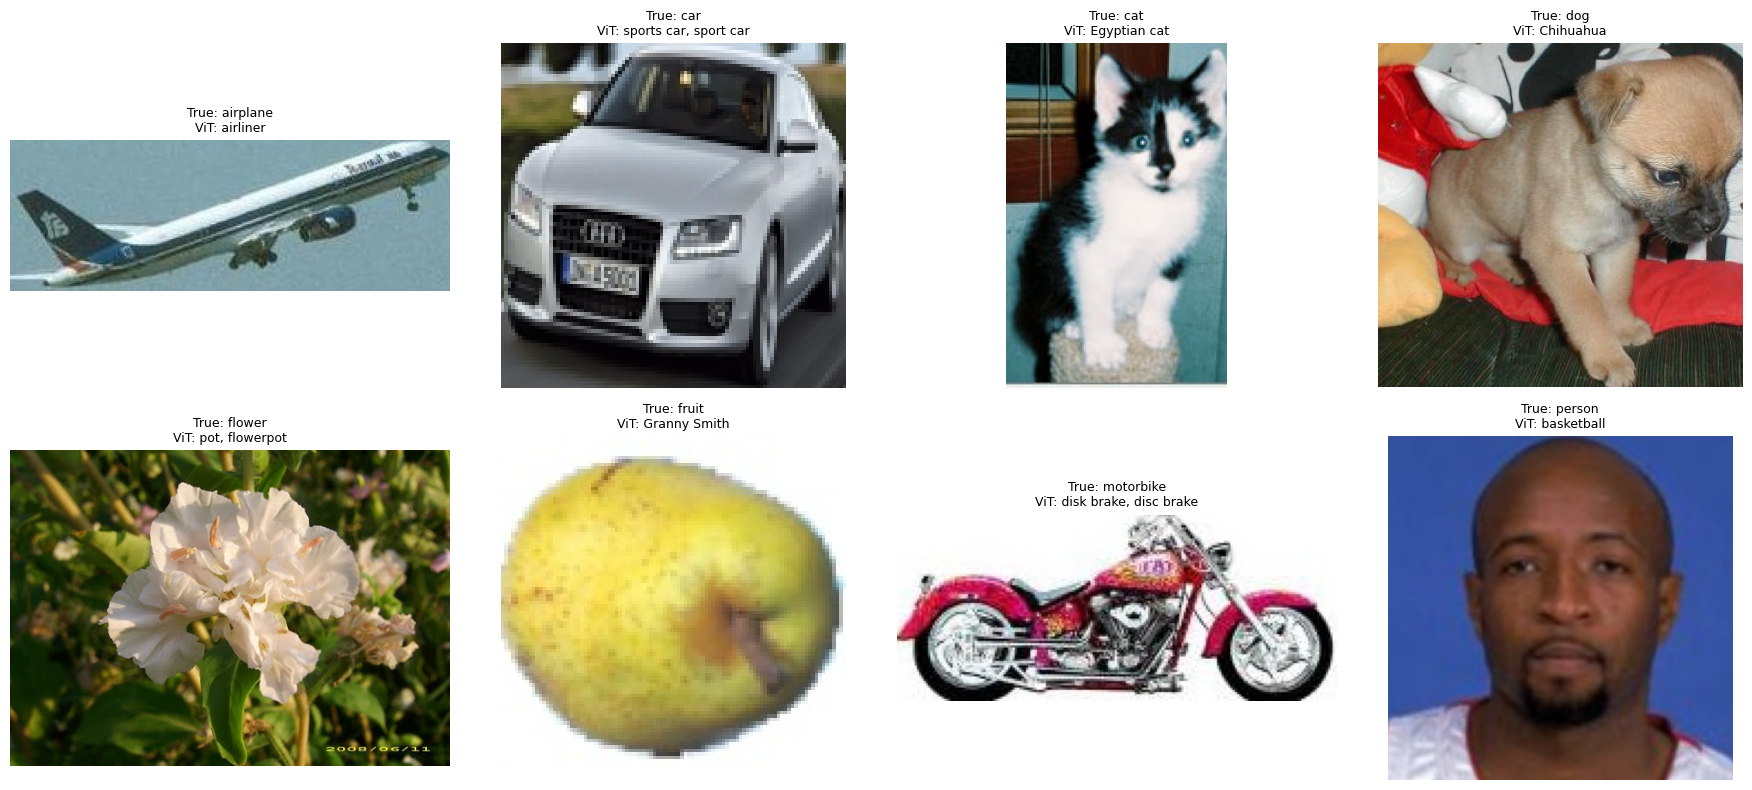

In [23]:
# Perform image classification on sample images using the Hugging Face ViT model,
# printing the image itself alongside the predicted class

plt.figure(figsize=(18, 8))

for i, image_path in enumerate(sample_image_paths):
    image = Image.open(image_path).convert('RGB')

    inputs = processor(images=image, return_tensors='pt')
    outputs = vit_model(**inputs)
    logits = outputs.logits
    predicted_class_index = logits.argmax(-1).item()
    predicted_label = vit_model.config.id2label[predicted_class_index]

    print("Image:", os.path.basename(image_path))
    print("True label:", sample_true_labels[i])
    print("ViT predicted label:", predicted_label)
    print("-" * 40)

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title(f"True: {sample_true_labels[i]}\nViT: {predicted_label}", fontsize=9)
    plt.axis('off')

plt.tight_layout()
plt.show()


Image: airplane_0334.jpg
  True label: airplane
  ResNet-50 (fine-tuned) prediction: airplane
  Hugging Face ViT prediction: airliner
--------------------------------------------------
Image: car_0895.jpg
  True label: car
  ResNet-50 (fine-tuned) prediction: car
  Hugging Face ViT prediction: sports car, sport car
--------------------------------------------------
Image: cat_0875.jpg
  True label: cat
  ResNet-50 (fine-tuned) prediction: cat
  Hugging Face ViT prediction: Egyptian cat
--------------------------------------------------
Image: dog_0200.jpg
  True label: dog
  ResNet-50 (fine-tuned) prediction: dog
  Hugging Face ViT prediction: Chihuahua
--------------------------------------------------
Image: flower_0626.jpg
  True label: flower
  ResNet-50 (fine-tuned) prediction: flower
  Hugging Face ViT prediction: pot, flowerpot
--------------------------------------------------
Image: fruit_0259.jpg
  True label: fruit
  ResNet-50 (fine-tuned) prediction: fruit
  Hugging Face Vi

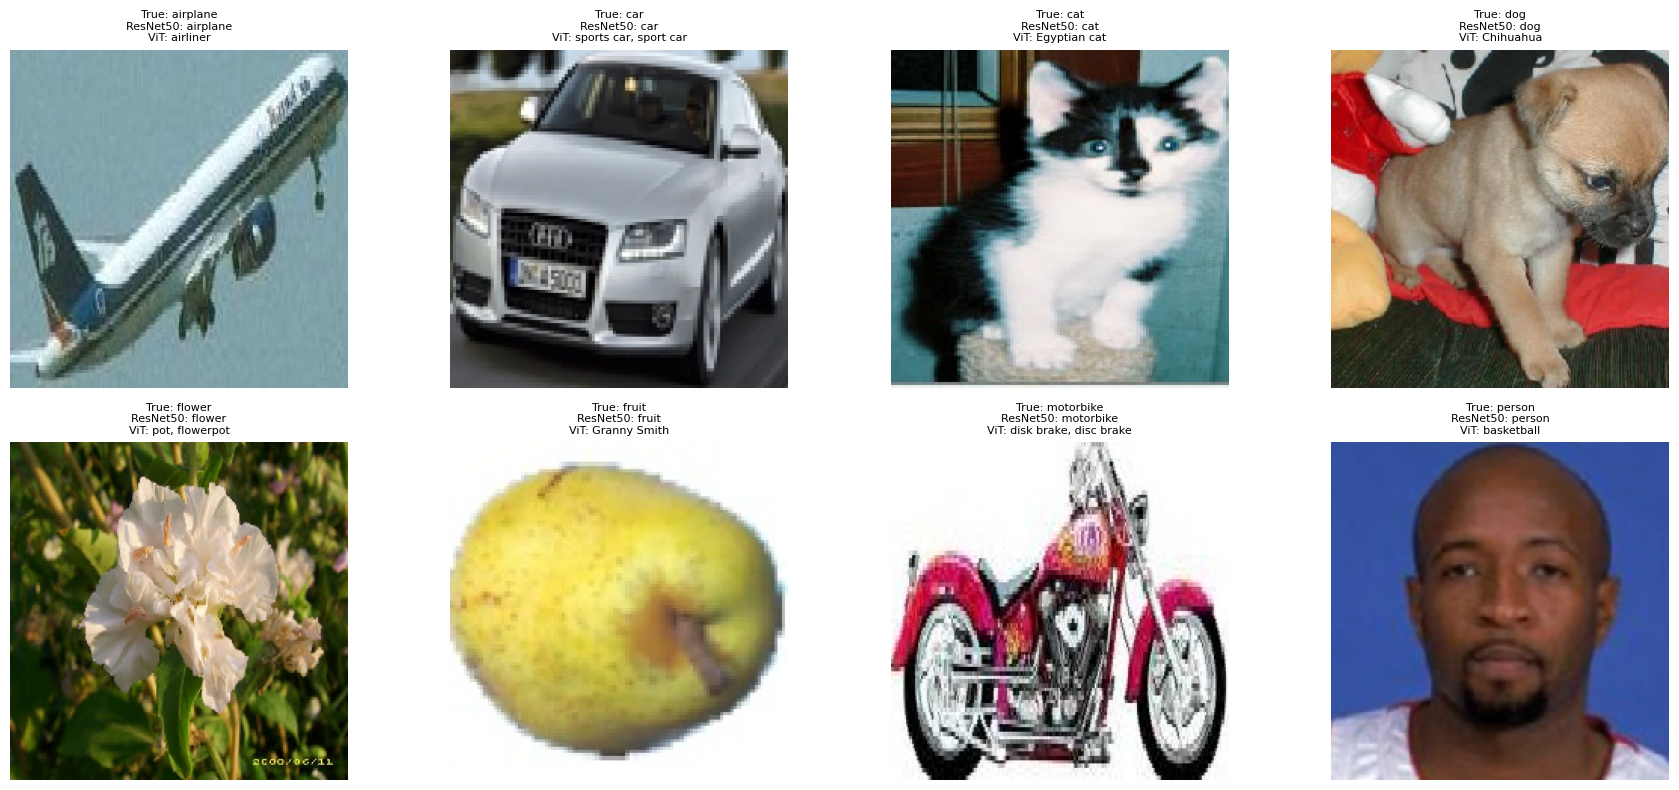

In [24]:
# Compare predictions with the transfer learning model (ResNet-50),
# again printing the image alongside both predicted classes.
# Note: we display the RAW image (0-255 / 255 for viewing), but feed the model a
# separately preprocessed copy using ResNet-50's own preprocess_input function.
from tensorflow.keras.preprocessing import image as keras_image

plt.figure(figsize=(18, 8))

for i, image_path in enumerate(sample_image_paths):
    # Load the raw image once
    img = keras_image.load_img(image_path, target_size=(img_height, img_width))
    raw_array = keras_image.img_to_array(img)

    # ResNet-50 prediction: use its own preprocessing, not a plain /255 rescale
    model_input = preprocess_input(np.expand_dims(raw_array.copy(), axis=0))
    resnet_prediction = model.predict(model_input, verbose=0)
    resnet_label = class_names[np.argmax(resnet_prediction)]

    # ViT prediction (Hugging Face pre-trained model)
    pil_image = Image.open(image_path).convert('RGB')
    inputs = processor(images=pil_image, return_tensors='pt')
    outputs = vit_model(**inputs)
    vit_predicted_index = outputs.logits.argmax(-1).item()
    vit_label = vit_model.config.id2label[vit_predicted_index]

    print("Image:", os.path.basename(image_path))
    print("  True label:", sample_true_labels[i])
    print("  ResNet-50 (fine-tuned) prediction:", resnet_label)
    print("  Hugging Face ViT prediction:", vit_label)
    print("-" * 50)

    # For display, use the raw pixel values scaled to 0-1 (NOT the preprocessed version)
    display_array = raw_array / 255.0
    plt.subplot(2, 4, i + 1)
    plt.imshow(display_array)
    plt.title(f"True: {sample_true_labels[i]}\nResNet50: {resnet_label}\nViT: {vit_label}", fontsize=8)
    plt.axis('off')

plt.tight_layout()
plt.show()
